<a href="https://colab.research.google.com/github/deva123932/CSA-4703-DL/blob/main/exp_12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment 12: CNN Architecture and Hyperparameter Comparison
This experiment aims to systematically compare different CNN architectures and hyperparameters on the CIFAR-10 dataset, focusing on balancing accuracy, parameter count, and training time for low-cost edge devices.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers
from tensorflow.keras.datasets import cifar10

# Load and preprocess CIFAR-10 dataset
(x_train, y_train), (x_test, y_test) = cifar10.load_data()
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

# Keep a smaller subset for faster experimentation training if resources are limited
# However, we will use the full set or a reasonable subset (e.g., 20,000 samples) to ensure meaningful learning rates comparisons.
SUBSET_SIZE = 20000
x_train_sub, y_train_sub = x_train[:SUBSET_SIZE], y_train[:SUBSET_SIZE]

# Global list to store experiment results
results = []

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1048s 6us/step


## Task 1: Vary the Number of Convolutional Layers (2, 3, 4)
We will keep other hyperparameters constant (3x3 filters, max pooling, no batch norm, default learning rate) and vary the depth.

In [2]:
def build_variable_depth_model(num_layers):
    model = models.Sequential()
    model.add(layers.Input(shape=(32, 32, 3)))

    for i in range(num_layers):
        filters = 32 * (2**i)
        model.add(layers.Conv2D(filters, (3, 3), activation='relu', padding='same'))
        model.add(layers.MaxPooling2D((2, 2)))

    model.add(layers.Flatten())
    model.add(layers.Dense(64, activation='relu'))
    model.add(layers.Dense(10, activation='softmax'))
    return model

for depth in [2, 3, 4]:
    model = build_variable_depth_model(depth)
    model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

    params = model.count_params()
    start_time = time.time()
    history = model.fit(x_train_sub, y_train_sub, epochs=3, batch_size=64, validation_split=0.1, verbose=0)
    elapsed_time = time.time() - start_time

    val_acc = history.history['val_accuracy'][-1]
    results.append({
        'Config': f'{depth} Conv Layers',
        'Params': params,
        'Train Time (s)': round(elapsed_time, 2),
        'Val Accuracy': round(val_acc, 4)
    })
    print(f'{depth} Layers - Params: {params}, Time: {elapsed_time:.1f}s, Val Acc: {val_acc:.4f}')

2 Layers - Params: 282250, Time: 104.8s, Val Acc: 0.5565
3 Layers - Params: 225034, Time: 123.5s, Val Acc: 0.5575
4 Layers - Params: 454666, Time: 181.8s, Val Acc: 0.5845


## Task 2: Vary Filter Size (3x3 vs 5x5) and Filter Count
We evaluate the performance impacts of standard 3x3 filter sizes versus larger 5x5 filters.

In [3]:
def build_filter_model(filter_size, base_filters):
    model = models.Sequential([
        layers.Input(shape=(32, 32, 3)),
        layers.Conv2D(base_filters, filter_size, activation='relu', padding='same'),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(base_filters * 2, filter_size, activation='relu', padding='same'),
        layers.MaxPooling2D((2, 2)),
        layers.Flatten(),
        layers.Dense(64, activation='relu'),
        layers.Dense(10, activation='softmax')
    ])
    return model

filter_configs = [
    ((3, 3), 32),
    ((5, 5), 32),
    ((3, 3), 64)
]

for f_size, f_count in filter_configs:
    model = build_filter_model(f_size, f_count)
    model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

    params = model.count_params()
    start_time = time.time()
    history = model.fit(x_train_sub, y_train_sub, epochs=3, batch_size=64, validation_split=0.1, verbose=0)
    elapsed_time = time.time() - start_time

    val_acc = history.history['val_accuracy'][-1]
    results.append({
        'Config': f'Filter {f_size[0]}x{f_size[1]}, Base {f_count}',
        'Params': params,
        'Train Time (s)': round(elapsed_time, 2),
        'Val Accuracy': round(val_acc, 4)
    })
    print(f'Filter {f_size[0]}x{f_size[1]}, Base {f_count} - Params: {params}, Time: {elapsed_time:.1f}s, Val Acc: {val_acc:.4f}')

Filter 3x3, Base 32 - Params: 282250, Time: 87.9s, Val Acc: 0.5770
Filter 5x5, Base 32 - Params: 316554, Time: 227.4s, Val Acc: 0.5145
Filter 3x3, Base 64 - Params: 600650, Time: 229.8s, Val Acc: 0.5975


## Task 3: Compare Max Pooling vs Average Pooling (With/Without Batch Normalization)

In [4]:
def build_pooling_bn_model(pooling_type, use_bn):
    model = models.Sequential()
    model.add(layers.Input(shape=(32, 32, 3)))

    for filters in [32, 64]:
        model.add(layers.Conv2D(filters, (3, 3), padding='same'))
        if use_bn:
            model.add(layers.BatchNormalization())
        model.add(layers.Activation('relu'))

        if pooling_type == 'max':
            model.add(layers.MaxPooling2D((2, 2)))
        else:
            model.add(layers.AveragePooling2D((2, 2)))

    model.add(layers.Flatten())
    model.add(layers.Dense(64, activation='relu'))
    model.add(layers.Dense(10, activation='softmax'))
    return model

pool_bn_configs = [
    ('max', False),
    ('avg', False),
    ('max', True),
    ('avg', True)
]

for pool, bn in pool_bn_configs:
    model = build_pooling_bn_model(pool, bn)
    model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

    params = model.count_params()
    start_time = time.time()
    history = model.fit(x_train_sub, y_train_sub, epochs=3, batch_size=64, validation_split=0.1, verbose=0)
    elapsed_time = time.time() - start_time

    val_acc = history.history['val_accuracy'][-1]
    results.append({
        'Config': f'Pool: {pool}, BN: {bn}',
        'Params': params,
        'Train Time (s)': round(elapsed_time, 2),
        'Val Accuracy': round(val_acc, 4)
    })
    print(f'Pool: {pool}, BN: {bn} - Params: {params}, Time: {elapsed_time:.1f}s, Val Acc: {val_acc:.4f}')

Pool: max, BN: False - Params: 282250, Time: 112.0s, Val Acc: 0.5750
Pool: avg, BN: False - Params: 282250, Time: 90.7s, Val Acc: 0.5375
Pool: max, BN: True - Params: 282634, Time: 123.4s, Val Acc: 0.5505
Pool: avg, BN: True - Params: 282634, Time: 106.9s, Val Acc: 0.4925


## Task 4: Vary Learning Rate and Batch Size

In [5]:
lr_batch_configs = [
    (0.01, 32),
    (0.001, 32),
    (0.001, 128)
]

for lr, bs in lr_batch_configs:
    # Using standard 3-layer architecture for baseline comparison
    model = build_variable_depth_model(3)
    opt = optimizers.Adam(learning_rate=lr)
    model.compile(optimizer=opt, loss='sparse_categorical_crossentropy', metrics=['accuracy'])

    params = model.count_params()
    start_time = time.time()
    history = model.fit(x_train_sub, y_train_sub, epochs=3, batch_size=bs, validation_split=0.1, verbose=0)
    elapsed_time = time.time() - start_time

    val_acc = history.history['val_accuracy'][-1]
    results.append({
        'Config': f'LR: {lr}, Batch Size: {bs}',
        'Params': params,
        'Train Time (s)': round(elapsed_time, 2),
        'Val Accuracy': round(val_acc, 4)
    })
    print(f'LR: {lr}, BS: {bs} - Params: {params}, Time: {elapsed_time:.1f}s, Val Acc: {val_acc:.4f}')

LR: 0.01, BS: 32 - Params: 225034, Time: 124.4s, Val Acc: 0.1025
LR: 0.001, BS: 32 - Params: 225034, Time: 128.7s, Val Acc: 0.6115
LR: 0.001, BS: 128 - Params: 225034, Time: 122.1s, Val Acc: 0.5625


## Task 5: Performance Summary Table and Analysis
We compile and display the architecture choices alongside parameter size, training time, and validation accuracy.

,Config,Params,Train Time (s),Val Accuracy
0,2 Conv Layers,282250,104.82,0.5565
1,3 Conv Layers,225034,123.48,0.5575
2,4 Conv Layers,454666,181.77,0.5845
3,"Filter 3x3, Base 32",282250,87.86,0.5770
4,"Filter 5x5, Base 32",316554,227.36,0.5145
5,"Filter 3x3, Base 64",600650,229.77,0.5975
6,"Pool: max, BN: False",282250,112.01,0.5750
7,"Pool: avg, BN: False",282250,90.67,0.5375
8,"Pool: max, BN: True",282634,123.43,0.5505
9,"Pool: avg, BN: True",282634,106.90,0.4925


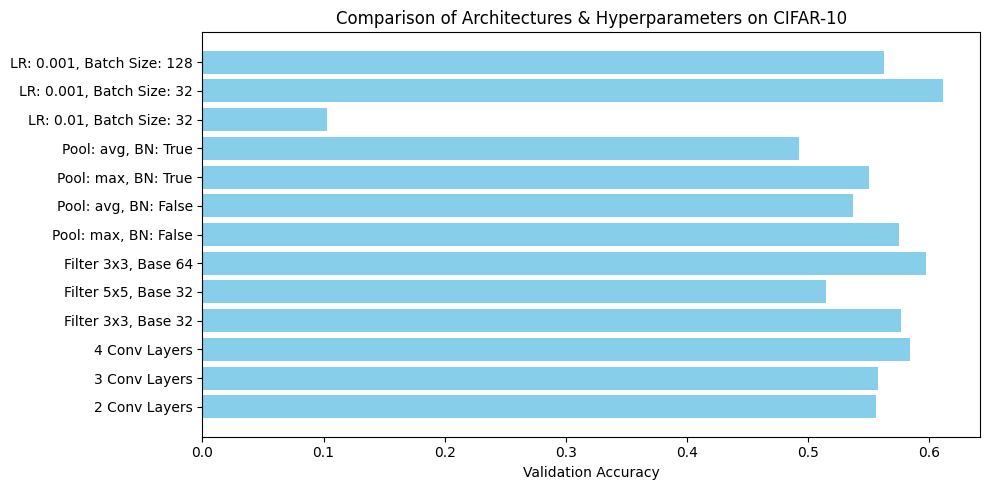

In [6]:
df_results = pd.DataFrame(results)
display(df_results)

# Visualize comparison
plt.figure(figsize=(10, 5))
plt.barh(df_results['Config'], df_results['Val Accuracy'], color='skyblue')
plt.xlabel('Validation Accuracy')
plt.title('Comparison of Architectures & Hyperparameters on CIFAR-10')
plt.tight_layout()
plt.show()